# Módulo 1: Monitoreo de Latencia, Consumo de Tokens y Costos por Invocación

## 1. Fundamentos Teóricos

Para evaluar y optimizar cualquier solución corporativa basada en LLMs y RAG, el primer paso cuantitativo consiste en **medir la eficiencia de recursos y el rendimiento temporal**. Antes de analizar la calidad semántica del texto, un arquitecto de IA debe controlar la latencia de respuesta y la contabilidad de uso de API.

### Uso de Tokens e Impacto Operativo

Los modelos de lenguaje procesan el texto dividiéndolo en unidades llamadas **tokens** (aproximadamente $1 \text{ token} \approx 0.75 \text{ palabras}$ en español). El consumo total de una llamada a la API se desglosa en dos variables críticas:

1. **Tokens de Entrada (*****Prompt Tokens*****):** Incluyen la instrucción del sistema, el historial conversacional y todos los fragmentos (*chunks*) recuperados del sistema RAG.
2. **Tokens de Salida (*****Completion Tokens*****):** Corresponden al texto generado directamente por el modelo.


### Medición de Latencia Operativa

En arquitecturas RAG, el tiempo total desde que el usuario envía su consulta hasta que recibe la respuesta ($T_{\text{total}}$) es la suma acumulada de varias fases:

$$
T_{\text{total}} = T_{\text{retrieval}} + T_{\text{prompt\_assembly}} + T_{\text{llm\_response}}
$$

Medir el tiempo de ejecución mediante contadores de alta precisión (como `time.perf_counter()`) junto con la inspección del objeto de metadatos de LangChain (`usage_metadata`) permite identificar si un retraso en la aplicación proviene de una búsqueda vectorial lenta o de una generación excesivamente extensa del modelo.


In [1]:
!pip install -q langchain-google-genai

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.6/79.6 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 571.5/571.5 kB 15.0 MB/s eta 0:00:00


In [3]:
import os
import time
from google.colab import userdata
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

# -------------------------------------------------------------------------
# Step 1: Configuración segura de variables de entorno y credenciales
# -------------------------------------------------------------------------
try:
    # Extracción de la API Key desde los secretos guardados en el entorno de Colab
    api_key_google = userdata.get('GOOGLE_API_KEY')
    os.environ["GOOGLE_API_KEY"] = api_key_google
    print("✅ Credenciales configuradas exitosamente.")
except Exception as e:
    print(f"❌ Error al cargar credenciales: {e}")
    print("Asegúrate de configurar 'GOOGLE_API_KEY' en los secretos de Colab.")

# -------------------------------------------------------------------------
# Step 2: Inicialización del LLM con LangChain
# -------------------------------------------------------------------------
# Se utiliza una temperatura baja (0.2) para mantener la estabilidad analítica
llm = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash",
    temperature=1
)

def evaluar_rendimiento_llm(instruccion_prompt: str, consulta_usuario: str):
    """
    Ejecuta una consulta sobre el LLM registrando el tiempo de ejecución (latencia)
    y extrayendo los metadatos de consumo de tokens retornados por LangChain.
    """
    # Definimos la plantilla de prompt estructurada
    prompt = ChatPromptTemplate.from_messages([
        ("system", "{instruccion}"),
        ("user", "{consulta}")
    ])

    # Creamos la cadena usando LangChain Expression Language (LCEL)
    cadena = prompt | llm

    # Marca de tiempo inicial con alta precisión
    tiempo_inicio = time.perf_counter()

    # Invocación de la cadena
    resultado = cadena.invoke({
        "instruccion": instruccion_prompt,
        "consulta": consulta_usuario
    })

    # Marca de tiempo final y cálculo del tiempo transcurrido
    tiempo_fin = time.perf_counter()
    latencia_segundos = tiempo_fin - tiempo_inicio

    # Extracción de metadatos de uso de tokens directamente desde el AIMessage de LangChain
    metadatos_uso = resultado.usage_metadata

    # Retornamos el contenido generado y las métricas recopiladas
    return {
        "respuesta": resultado.content,
        "latencia_s": round(latencia_segundos, 3),
        "prompt_tokens": metadatos_uso.get("input_tokens", 0) if metadatos_uso else 0,
        "completion_tokens": metadatos_uso.get("output_tokens", 0) if metadatos_uso else 0,
        "total_tokens": metadatos_uso.get("total_tokens", 0) if metadatos_uso else 0
    }


instruccion = (
    "Eres un auditor de proyectos de TI en Chile. Analiza el siguiente escenario "
    "y entrega un diagnóstico breve enfocado en la arquitectura de datos."
)

caso_estudio = (
    "En un proyecto académico en Chile, se desarrolló un asistente con IA generativa "
    "para responder consultas técnicas usando información interna y externa. Aunque "
    "el sistema entregaba respuestas rápidas, muchas veces estas eran poco precisas "
    "o no consideraban correctamente el contexto."
)

print("\n[EVALUACIÓN] Ejecutando consulta y midiendo telemetría...")

# Invocación del experimento
metricas = evaluar_rendimiento_llm(instruccion, caso_estudio)

# -------------------------------------------------------------------------
# Step 5: Visualización de resultados del diagnóstico
# -------------------------------------------------------------------------
print("\n=== RESPUESTA GENERADA ===")
print(metricas["respuesta"])

print("\n=== MÉTRICAS DE RENDIMIENTO Y OPTIMIZACIÓN ===")
print(f"⏱️ Latencia Total:          {metricas['latencia_s']} segundos")
print(f"📥 Tokens de Entrada (Input): {metricas['prompt_tokens']} tokens")
print(f"📤 Tokens de Salida (Output): {metricas['completion_tokens']} tokens")
print(f"📊 Total de Tokens Usados:   {metricas['total_tokens']} tokens")

✅ Credenciales configuradas exitosamente.

[EVALUACIÓN] Ejecutando consulta y midiendo telemetría...

=== RESPUESTA GENERADA ===
[{'type': 'text', 'text': 'Estimado equipo del proyecto,\n\nComo auditor de TI, he analizado el escenario del asistente de IA generativa. A continuación, presento el diagnóstico de la **Arquitectura de Datos**, identificando las brechas que causan la falta de precisión (alucinaciones) y pérdida de contexto, a pesar de la óptima latencia del sistema.\n\n---\n\n### **DIAGNÓSTICO DE ARQUITECTURA DE DATOS**\n\nEl sistema presenta un comportamiento típico de una implementación de **RAG (Retrieval-Augmented Generation) deficiente**. La arquitectura actual prioriza la velocidad de respuesta (cómputo/red) pero descuida la calidad, estructura y relevancia de los datos que alimentan al modelo fundacional.\n\n#### **1. Hallazgos Principales (Brechas Detectadas)**\n\n*   **Estrategia de Fragmentación (Chunking) Inadecuada:** Los documentos internos y externos probablemen

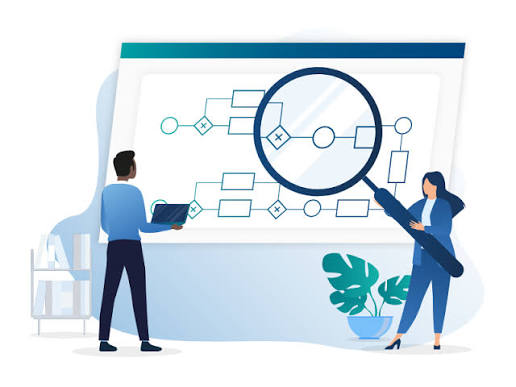

# Módulo 2: Medición de Fidelidad (*Faithfulness*) y Detección de Alucinaciones con LLM-as-a-Judge

## 1. Fundamentos Teóricos

En sistemas RAG corporativos, una de las fallas más críticas es la **alucinación**: cuando el modelo genera afirmaciones plausibles pero que no están respaldadas por el contexto recuperado desde la base de conocimientos.

Para medir de manera cuantitativa si una respuesta es 100% fiel al texto fuente, se utiliza el patrón **LLM-as-a-Judge** (*El LLM como Juez*).


### El Concepto de Fidelidad (*Faithfulness*)

La **fidelidad** evalúa la proporción de afirmaciones presentes en la respuesta que se derivan estrictamente del contexto provisto.

$$
\text{Fidelidad} =
\frac{\text{Número de afirmaciones en la respuesta respaldadas por el contexto}}
{\text{Número total de afirmaciones expresadas en la respuesta}}
$$

* **Fidelidad = 1.0:** Toda la información entregada está respaldada por los documentos recuperados. No hay alucinaciones.
* **Fidelidad < 1.0:** El modelo introdujo conocimientos previos no presentes en el contexto corporativo o distorsionó los hechos presentados.

### Metodología LLM-as-a-Judge con Formato Estructurado

Para implementar este evaluador en LangChain sin depender de librerías externas complejas, se diseña una **cadena de evaluación** que obliga al modelo a actuar como un auditor imparcial. La instrucción exige:

1. Extraer las afirmaciones clave de la respuesta.
2. Comprobar cada afirmación individualmente contra el contexto.
3. Devolver un puntaje numérico en formato JSON estructurado junto con la justificación técnica.


In [4]:
import os
import json
from google.colab import userdata
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

try:
    api_key_google = userdata.get('GOOGLE_API_KEY')
    os.environ["GOOGLE_API_KEY"] = api_key_google
    print("✅ Credenciales configuradas exitosamente.")
except Exception as e:
    print(f"❌ Error al cargar credenciales: {e}")

# Modelo para la tarea principal (Generador)
llm_generador = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash",
    temperature=0.3
)

# Modelo para la auditoría (Juez): Usamos temperatura 0.0 para maximizar el determinismo
llm_juez = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash",
    temperature=0.0
)

# Prompt estructurado que obliga al juez a responder en JSON estricto
prompt_evaluador_fidelidad = ChatPromptTemplate.from_messages([
    ("system", (
        "Eres un auditor técnico riguroso de IA. Tu trabajo es evaluar la FIDELIDAD "
        "de una respuesta generada respecto a un CONTEXTO provisto.\n\n"
        "Reglas de evaluación:\n"
        "1. Analiza cada afirmación en la RESPUESTA.\n"
        "2. Comprueba si está respaldada explícitamente en el CONTEXTO.\n"
        "3. Si la respuesta contiene información que NO está en el contexto (alucinación o conocimiento externo), penaliza el puntaje.\n"
        "4. Devuelve ÚNICAMENTE un objeto JSON válido con este formato exacto:\n"
        "{{\n"
        '  "afirmaciones_evaluadas": ["afirmacion 1", "afirmacion 2"],\n'
        '  "afirmaciones_alucinadas": ["afirmacion no respaldada si existe"],\n'
        '  "puntaje_fidelidad": 0.0 a 1.0,\n'
        '  "justificacion": "Explicación breve del veredicto"\n'
        "}}\n"
    )),
    ("user", "CONTEXTO:\n{contexto}\n\nRESPUESTA A EVALUAR:\n{respuesta}")
])

cadena_juez = prompt_evaluador_fidelidad | llm_juez | StrOutputParser()

contexto_corporativo = (
    "En el proyecto de IA en Chile, el asistente técnico utilizaba un vector store "
    "configurado con fragmentos de 1000 tokens sin solapamiento (overlap). Esto provocaba "
    "que las oraciones importantes quedaran cortadas entre chunks, perdiendo el contexto "
    "original de las consultas sobre la base de datos de mantenimiento."
)

# Caso A: Respuesta basada 100% en el contexto
respuesta_fiel = (
    "Las consultas fallaban porque los fragmentos de 1000 tokens no tenían solapamiento, "
    "lo que cortaba las oraciones entre chunks y causaba la pérdida del contexto original."
)

# Caso B: Respuesta razonable pero con información alucinada/externa no presente en el texto
respuesta_alucinada = (
    "El problema principal era que la base de datos PostgreSQL estaba desactualizada "
    "y el modelo Gemini no tenía suficiente memoria RAM para procesar los datos de mantenimiento."
)

print("\n[EVALUACIÓN 1] Analizando Respuesta Fiel...")
evaluacion_a = cadena_juez.invoke({
    "contexto": contexto_corporativo,
    "respuesta": respuesta_fiel
})

print("\n[EVALUACIÓN 2] Analizando Respuesta con Alucinaciones...")
evaluacion_b = cadena_juez.invoke({
    "contexto": contexto_corporativo,
    "respuesta": respuesta_alucinada
})

def mostrar_resultado_evaluacion(titulo, raw_json):
    print(f"\n==================== {titulo} ====================")
    try:
        # Limpieza básica por si el modelo incluye bloques de código markdown ```json
        json_limpio = raw_json.strip().replace("```json", "").replace("```", "").strip()
        data = json.loads(json_limpio)
        print(f"📊 Puntaje Fidelidad:      {data.get('puntaje_fidelidad')}")
        print(f"📝 Justificación:          {data.get('justificacion')}")
        print(f"🔍 Afirmaciones Evaluadas:  {data.get('afirmaciones_evaluadas')}")
        print(f"⚠️ Alucinaciones Detectadas: {data.get('afirmaciones_alucinadas')}")
    except Exception as err:
        print(f"Error al parsear JSON: {err}\nSalida bruta:\n{raw_json}")

mostrar_resultado_evaluacion("CASO A: RESPUESTA FIEL", evaluacion_a)
mostrar_resultado_evaluacion("CASO B: RESPUESTA ALUCINADA", evaluacion_b)

✅ Credenciales configuradas exitosamente.

[EVALUACIÓN 1] Analizando Respuesta Fiel...

[EVALUACIÓN 2] Analizando Respuesta con Alucinaciones...

==================== CASO A: RESPUESTA FIEL ====================
📊 Puntaje Fidelidad:      0.85
📝 Justificación:          La respuesta es casi totalmente fiel al contexto, explicando correctamente la configuración de los fragmentos y la pérdida de contexto. Sin embargo, introduce una pequeña extrapolación al afirmar que las consultas 'fallaban', cuando el contexto únicamente menciona que se 'perdía el contexto original de las consultas'.
🔍 Afirmaciones Evaluadas:  ['Las consultas fallaban', 'Los fragmentos de 1000 tokens no tenían solapamiento', 'Se cortaban las oraciones entre chunks', 'Se causaba la pérdida del contexto original']
⚠️ Alucinaciones Detectadas: ['Las consultas fallaban']

==================== CASO B: RESPUESTA ALUCINADA ====================
📊 Puntaje Fidelidad:      0.0
📝 Justificación:          La respuesta es completamente 

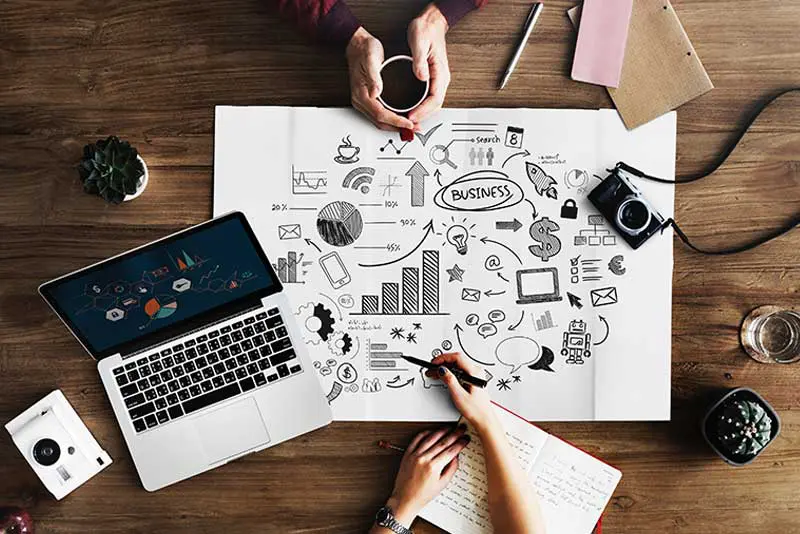

# Módulo 3: Evaluación de Relevancia del Contexto (*Context Relevance*) y Limpieza de Chunks

## 1. Fundamentos Teóricos

En arquitecturas RAG, incluir fragmentos de texto (*chunks*) irrelevantes, ruidosos o demasiado extensos contamina la ventana de contexto del LLM. Este fenómeno provoca dos problemas principales:

1. **Efecto "Lost in the Middle":** Los modelos de lenguaje tienden a prestar mayor atención a la información ubicada al principio o al final del prompt, omitiendo detalles cruciales sepultados en medio de chunks ruidosos.
2. **Desperdicio de Tokens y Costos Elevados:** Procesar texto irrelevante incrementa la latencia y el consumo inútil de tokens de entrada (*input tokens*).

Para medir cuantitativamente si el motor de búsqueda vectorial (*Retriever*) está recuperando información limpia y directamente asociada a la pregunta del usuario, calculamos la métrica de **Relevancia del Contexto (*****Context Relevance*****)**.


### Cálculo de la Relevancia del Contexto

La **Relevancia del Contexto** evalúa la proporción de oraciones o fragmentos recuperados por el *Retriever* que son estrictamente necesarios para responder la consulta:

$$
\text{Relevancia del Contexto} =
\frac{\text{Número de oraciones/sentencias relevantes en los Chunks recuperados}}
{\text{Número total de oraciones/sentencias contenidas en todos los Chunks}}
$$

* **Relevancia = 1.0:** Todo el texto entregado al LLM es pertinente y útil para responder la pregunta.
* **Relevancia < 0.5:** Más de la mitad del contexto inyectado es "ruido" (información no relacionada, encabezados irrelevantes o texto duplicado).


In [5]:
import os
import json
from google.colab import userdata
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

try:
    api_key_google = userdata.get('GOOGLE_API_KEY')
    os.environ["GOOGLE_API_KEY"] = api_key_google
    print("✅ Credenciales configuradas exitosamente.")
except Exception as e:
    print(f"❌ Error al cargar credenciales: {e}")

# Se utiliza temperatura 0.0 para un análisis determinista e imparcial
llm_juez = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash",
    temperature=0.0
)

prompt_relevancia_contexto = ChatPromptTemplate.from_messages([
    ("system", (
        "Eres un analista técnico de arquitectura de información para IA. "
        "Tu tarea es evaluar la RELEVANCIA del CONTEXTO recuperado respecto a una PREGUNTA dada.\n\n"
        "Instrucciones:\n"
        "1. Revisa cada oración del CONTEXTO.\n"
        "2. Identifica las oraciones que contienen datos ÚTILES para responder la PREGUNTA.\n"
        "3. Identifica las oraciones que son RUIDO o IRRELEVANTES.\n"
        "4. Devuelve ÚNICAMENTE un objeto JSON válido con este formato exacto:\n"
        "{{\n"
        '  "oraciones_relevantes": ["oracion util 1", "oracion util 2"],\n'
        '  "oraciones_irrelevantes": ["oracion ruidosa 1"],\n'
        '  "puntaje_relevancia": 0.0 a 1.0,\n'
        '  "diagnostico": "Explicación breve de la calidad de la segmentación"\n'
        "}}\n"
    )),
    ("user", "PREGUNTA:\n{pregunta}\n\nCONTEXTO RECUPERADO:\n{contexto}")
])

cadena_evaluadora_contexto = prompt_relevancia_contexto | llm_juez | StrOutputParser()

pregunta_usuario = "¿Qué herramientas se utilizarán en la Semana 3 para evaluar y optimizar RAG?"

# Contexto con mezcla de información relevante y ruido de gestión corporativa/administrativa
contexto_ruidoso_recuperado = (
    "En la Semana 3 abordaremos cómo la gestión del flujo de información impacta en la precisión "
    "de las respuestas mediante el uso de LangChain. "
    "Recuerden registrar su asistencia en el portal institucional antes de las 23:59 hrs. "
    "Además, evaluaremos sistemas mediante herramientas especializadas como LangSmith para monitorear seguridad en producción. "
    "El casino de la universidad estará cerrado por mantención durante el fin de semana largo. "
    "Revisaremos en detalle la arquitectura de Vector RAG y la segmentación de chunks."
)

print("\n[EVALUACIÓN] Analizando la calidad del contexto recuperado...")

resultado_raw = cadena_evaluadora_contexto.invoke({
    "pregunta": pregunta_usuario,
    "contexto": contexto_ruidoso_recuperado
})

print("\n==================== RESULTADO DE AUDITORÍA DE CONTEXTO ====================")
try:
    json_limpio = resultado_raw.strip().replace("```json", "").replace("```", "").strip()
    data = json.loads(json_limpio)

    print(f"📊 Puntaje Relevancia Contexto: {data.get('puntaje_relevancia')}")
    print(f"📝 Diagnóstico:                {data.get('diagnostico')}")
    print(f"\n✅ Oraciones Útiles ({len(data.get('oraciones_relevantes', []))}):")
    for o in data.get('oraciones_relevantes', []):
        print(f"   • {o}")

    print(f"\n🗑️ Ruido Eliminado ({len(data.get('oraciones_irrelevantes', []))}):")
    for o in data.get('oraciones_irrelevantes', []):
        print(f"   • {o}")

except Exception as err:
    print(f"Error al parsear el JSON de evaluación: {err}\nSalida bruta:\n{resultado_raw}")

✅ Credenciales configuradas exitosamente.

[EVALUACIÓN] Analizando la calidad del contexto recuperado...

==================== RESULTADO DE AUDITORÍA DE CONTEXTO ====================
📊 Puntaje Relevancia Contexto: 0.4
📝 Diagnóstico:                El contexto identifica claramente dos herramientas clave (LangChain y LangSmith) para el desarrollo y evaluación en la Semana 3. Sin embargo, contiene bastante ruido en forma de anuncios administrativos y detalles temáticos que no responden directamente a la pregunta sobre herramientas.

✅ Oraciones Útiles (2):
   • En la Semana 3 abordaremos cómo la gestión del flujo de información impacta en la precisión de las respuestas mediante el uso de LangChain.
   • Además, evaluaremos sistemas mediante herramientas especializadas como LangSmith para monitorear seguridad en producción.

🗑️ Ruido Eliminado (3):
   • Recuerden registrar su asistencia en el portal institucional antes de las 23:59 hrs.
   • El casino de la universidad estará cerrado por 

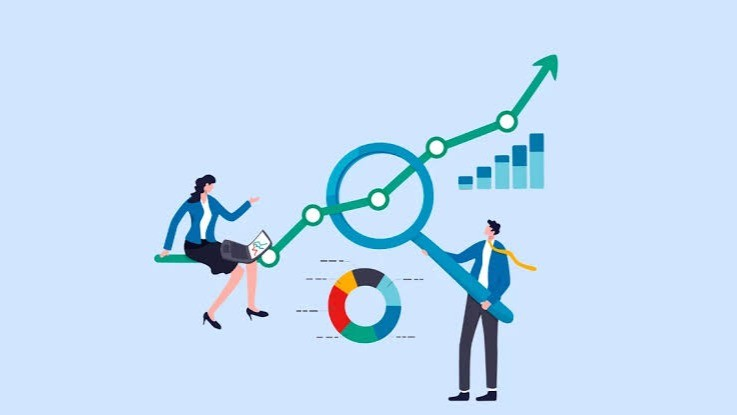

# Módulo 4: Evaluación de Relevancia de la Respuesta (*Answer Relevance*) respecto a la Consulta

## 1. Fundamentos Teóricos

Incluso cuando un sistema RAG recupera el contexto correcto y no comete alucinaciones, puede incurrir en otro tipo de fallo: la **falta de relevancia en la respuesta**. Esto ocurre cuando el modelo de lenguaje genera un texto técnicamente verídico pero evasivo, incompleto o que no responde directamente a lo que el usuario preguntó.


### El Concepto de Relevancia de la Respuesta (*Answer Relevance*)

La **Relevancia de la Respuesta** mide qué tan alineada está la respuesta generada con la intención original de la pregunta planteada.

$$
\text{Relevancia de la Respuesta} =
\frac{\text{Número de puntos de la consulta abordados directamente por la respuesta}}
{\text{Número total de puntos/aspectos requeridos en la consulta}}
$$

* **Diferencia entre Fidelidad y Relevancia:**

  * **Fidelidad (*****Faithfulness*****):** Compara *Respuesta vs. Contexto Recuperado* (Asegura que no haya alucinaciones).
  * **Relevancia de la Respuesta (*****Answer Relevance*****):** Compara *Respuesta vs. Consulta Original* (Asegura que la pregunta quede efectivamente contestada).
* **Puntajes característicos:**

  * **1.0:** La respuesta aborda directamente todos los aspectos de la consulta con el nivel de detalle requerido.
  * **0.5:** La respuesta contesta solo una parte de la pregunta o se desvía en explicaciones secundarias.
  * **0.0:** La respuesta es una evasiva ("No tengo suficiente información") o responde a algo completamente distinto a lo consultado.


In [6]:
import os
import json
from google.colab import userdata
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

try:
    api_key_google = userdata.get('GOOGLE_API_KEY')
    os.environ["GOOGLE_API_KEY"] = api_key_google
    print("✅ Credenciales configuradas exitosamente.")
except Exception as e:
    print(f"❌ Error al cargar credenciales: {e}")

# Se utiliza temperatura 0.0 para un análisis determinista y reproducible
llm_juez = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash",
    temperature=0.0
)

prompt_relevancia_respuesta = ChatPromptTemplate.from_messages([
    ("system", (
        "Eres un auditor técnico especializado en evaluar interfaces conversacionales e IA.\n"
        "Tu tarea es evaluar la RELEVANCIA DE LA RESPUESTA con respecto a la PREGUNTA DEL USUARIO.\n\n"
        "Criterios de evaluación:\n"
        "1. Revisa la intencionalidad y los requerimientos específicos de la PREGUNTA.\n"
        "2. Verifica si la RESPUESTA aborda directamente cada punto solicitado.\n"
        "3. Penaliza respuestas evasivas, redundantes, parcialmente incompletas o que se desvíen del tema principal.\n"
        "4. Devuelve ÚNICAMENTE un objeto JSON válido con el siguiente formato exacto:\n"
        "{{\n"
        '  "aspectos_preguntados": ["aspecto 1", "aspecto 2"],\n'
        '  "aspectos_respondidos": ["aspecto respondido"],\n'
        '  "aspectos_omitidos": ["aspecto faltante o evadido"],\n'
        '  "puntaje_relevancia_respuesta": 0.0 a 1.0,\n'
        '  "diagnostico": "Explicación breve del nivel de alineación y completitud"\n'
        "}}\n"
    )),
    ("user", "PREGUNTA DEL USUARIO:\n{pregunta}\n\nRESPUESTA DE LA IA:\n{respuesta}")
])

cadena_evaluadora_respuesta = prompt_relevancia_respuesta | llm_juez | StrOutputParser()

pregunta_compleja = (
    "¿Cuáles son las fechas de inicio de la Semana 4 y cuáles son los dos tipos "
    "de evaluaciones que comienzan en esta etapa de la asignatura?"
)

# Caso A: Respuesta completa y directa
respuesta_excelente = (
    "La Semana 4 inicia el lunes 31 de agosto de 2026. En esta etapa se da inicio "
    "a dos tipos de evaluaciones: la Evaluación Formativa y la Evaluación Sumativa."
)

# Caso B: Respuesta vaga y parcialmente evasiva (omite la fecha exacta)
respuesta_deficiente = (
    "En la Semana 4 de la asignatura Ingeniería de Soluciones con Inteligencia Artificial "
    "se da inicio a los procesos de evaluación de los estudiantes."
)

print("\n[EVALUACIÓN 1] Analizando Respuesta Directa y Completa...")
resultado_a = cadena_evaluadora_respuesta.invoke({
    "pregunta": pregunta_compleja,
    "respuesta": respuesta_excelente
})

print("\n[EVALUACIÓN 2] Analizando Respuesta Evasiva/Incompleta...")
resultado_b = cadena_evaluadora_respuesta.invoke({
    "pregunta": pregunta_compleja,
    "respuesta": respuesta_deficiente
})

def mostrar_diagnostico_respuesta(titulo, raw_json):
    print(f"\n==================== {titulo} ====================")
    try:
        json_limpio = raw_json.strip().replace("```json", "").replace("```", "").strip()
        data = json.loads(json_limpio)
        print(f"📊 Puntaje Relevancia Respuesta: {data.get('puntaje_relevancia_respuesta')}")
        print(f"📝 Diagnóstico:                   {data.get('diagnostico')}")
        print(f"🎯 Aspectos Solicitados:          {data.get('aspectos_preguntados')}")
        print(f"✅ Aspectos Respondidos:           {data.get('aspectos_respondidos')}")
        print(f"⚠️ Aspectos Omitidos:              {data.get('aspectos_omitidos')}")
    except Exception as err:
        print(f"Error al parsear el JSON de evaluación: {err}\nSalida bruta:\n{raw_json}")

mostrar_diagnostico_respuesta("CASO A: RESPUESTA COMPLETA", resultado_a)
mostrar_diagnostico_respuesta("CASO B: RESPUESTA INCOMPLETA", resultado_b)

✅ Credenciales configuradas exitosamente.

[EVALUACIÓN 1] Analizando Respuesta Directa y Completa...

[EVALUACIÓN 2] Analizando Respuesta Evasiva/Incompleta...

==================== CASO A: RESPUESTA COMPLETA ====================
📊 Puntaje Relevancia Respuesta: 1.0
📝 Diagnóstico:                   La respuesta es directa, precisa y responde completamente a los dos aspectos solicitados por el usuario sin rodeos ni omisiones.
🎯 Aspectos Solicitados:          ['Fecha de inicio de la Semana 4', 'Los dos tipos de evaluaciones que comienzan en la Semana 4']
✅ Aspectos Respondidos:           ['Fecha de inicio de la Semana 4 (lunes 31 de agosto de 2026)', 'Los dos tipos de evaluaciones que comienzan en esta etapa (Evaluación Formativa y Evaluación Sumativa)']
⚠️ Aspectos Omitidos:              []

==================== CASO B: RESPUESTA INCOMPLETA ====================
📊 Puntaje Relevancia Respuesta: 0.1
📝 Diagnóstico:                   La respuesta es extremadamente incompleta. Aunque menciona 

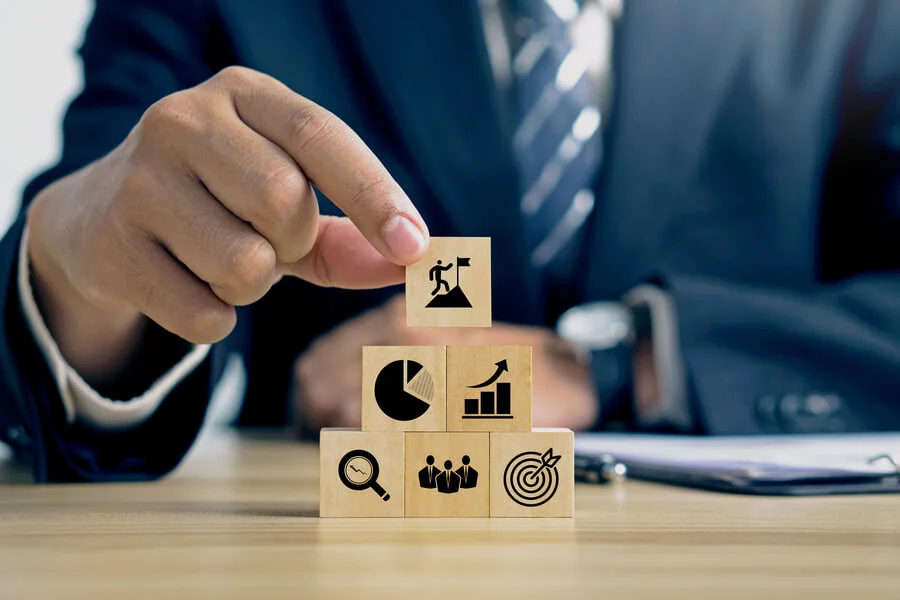

# Módulo 5: Optimización de Recuperación Vectorial mediante Búsqueda MM-R (*Maximal Marginal Relevance*)

## 1. Fundamentos Teóricos

En motores de búsqueda vectorial tradicionales (basados únicamente en **similitud de coseno** o distancia euclidiana), el *Retriever* recupera los $k$ documentos más cercanos a la representación vectorial (*embedding*) de la consulta.

Sin embargo, en corpus corporativos esto genera un problema recurrente: la **redundancia de información**. Si tres fragmentos (*chunks*) expresan la misma idea con distintas palabras, el motor tradicional devolverá los tres, ocupando valioso espacio en la ventana de contexto e ignorando otros aspectos de la pregunta.


### El Algoritmo Maximal Marginal Relevance (MM-R)

**MM-R** es un algoritmo de reordenamiento que equilibra dos objetivos contrapuestos:

1. **Relevancia:** Qué tan similar es el fragmento respecto a la consulta del usuario.
2. **Diversidad:** Qué tan diferente es el fragmento respecto a los documentos que *ya han sido seleccionados* previamente.

La fórmula del algoritmo MM-R se define mediante:

$$
\text{MMR} =
\arg\max_{d_i \in R \setminus S}
\left[
\lambda \cdot \text{Sim}_1(d_i, Q)
-
(1 - \lambda) \cdot
\max_{d_j \in S} \text{Sim}_2(d_i, d_j)
\right]
$$

Donde:

* $Q$ es la consulta del usuario.
* $R$ es el conjunto de documentos candidatos recuperados.
* $S$ es el conjunto de documentos ya seleccionados en la lista final.
* $\text{Sim}_1$ mide la similitud entre el documento y la consulta.
* $\text{Sim}_2$ mide la similitud entre el documento evaluado y los ya seleccionados.
* $\lambda$ (Lambda) es un hiperparámetro de ajuste entre $0.0$ y $1.0$:

  * **$\lambda = 1.0$:** Búsqueda vectorial tradicional pura (mÁxima relevancia, cero diversidad).
  * **$\lambda = 0.0$:** Máxima diversidad posible (ignora la relevancia directa con la consulta).
  * **$\lambda = 0.5$:** Balance equilibrado (estándar recomendado para RAG).


In [7]:
!pip install -q U langchain-community faiss-cpu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 47.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 88.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 36.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 2.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


In [8]:
import os
from google.colab import userdata
from langchain_google_genai import GoogleGenerativeAIEmbeddings
from langchain_community.vectorstores import FAISS
from langchain_core.documents import Document

try:
    api_key_google = userdata.get('GOOGLE_API_KEY')
    os.environ["GOOGLE_API_KEY"] = api_key_google
    print("✅ Credenciales configuradas exitosamente.")
except Exception as e:
    print(f"❌ Error al cargar credenciales: {e}")

# Usamos el modelo optimizado de embeddings de Google Generative AI
embeddings = GoogleGenerativeAIEmbeddings(
    model="gemini-embedding-2"
)

# Simulamos fragmentos extraídos de la asignatura con alta redundancia intencional
documentos_corporativos = [
    Document(
        page_content="LangChain permite estructurar pipelines de RAG conectando bases de conocimiento externas a LLMs.",
        metadata={"id": 1, "tema": "RAG Básica"}
    ),
    Document(
        page_content="RAG con LangChain facilita la integración de datos externos corporativos para alimentar modelos de lenguaje.",
        metadata={"id": 2, "tema": "RAG Básica Redundante"}
    ),
    Document(
        page_content="La arquitectura RAG integrada en LangChain conecta fuentes de conocimiento evitando la alucinación de respuestas.",
        metadata={"id": 3, "tema": "RAG Básica Redundante"}
    ),
    Document(
        page_content="Para evaluar la precisión en RAG se utilizan métricas como Fidelidad, Relevancia del Contexto y Relevancia de Respuesta.",
        metadata={"id": 4, "tema": "Evaluación RAG"}
    ),
    Document(
        page_content="LangSmith permite auditar y monitorear la latencia, el costo de tokens y los trazos de ejecución en producción.",
        metadata={"id": 5, "tema": "Monitoreo/LangSmith"}
    )
]

print("\n[INDEXACIÓN] Indexando documentos en la base de datos vectorial FAISS...")
vectorstore = FAISS.from_documents(documentos_corporativos, embeddings)

pregunta_usuario = "¿Cómo se implementa y se evalúa una solución RAG corporativa?"

print(f"\n🔍 CONSULTA: '{pregunta_usuario}'")

# --- EXPERIMENTO A: Búsqueda Vectorial Tradicional (Similitud Pura) ---
print("\n==================== EXPERIMENTO A: SIMILITUD DE COSENO TRADICIONAL (k=3) ====================")
docs_similitud = vectorstore.similarity_search(pregunta_usuario, k=3)

for i, doc in enumerate(docs_similitud, 1):
    print(f"\n[Chunk {i}] (ID: {doc.metadata['id']} | Tema: {doc.metadata['tema']})")
    print(f"  Contenido: {doc.page_content}")

# --- EXPERIMENTO B: Búsqueda con MM-R (Maximal Marginal Relevance) ---
print("\n==================== EXPERIMENTO B: BÚSQUEDA DIVERSA CON MM-R (k=3, Lambda=0.5) ====================")
docs_mmr = vectorstore.max_marginal_relevance_search(
    query=pregunta_usuario,
    k=3,
    fetch_k=5,   # Recupera 5 candidatos iniciales y selecciona los 3 más diversos
    lambda_mult=0.5 # Balance equilibrado entre relevancia y diversidad
)

for i, doc in enumerate(docs_mmr, 1):
    print(f"\n[Chunk {i}] (ID: {doc.metadata['id']} | Tema: {doc.metadata['tema']})")
    print(f"  Contenido: {doc.page_content}")

/tmp/ipykernel_1724/3484089403.py:4: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.vectorstores import FAISS


✅ Credenciales configuradas exitosamente.

[INDEXACIÓN] Indexando documentos en la base de datos vectorial FAISS...

🔍 CONSULTA: '¿Cómo se implementa y se evalúa una solución RAG corporativa?'

==================== EXPERIMENTO A: SIMILITUD DE COSENO TRADICIONAL (k=3) ====================

[Chunk 1] (ID: 2 | Tema: RAG Básica Redundante)
  Contenido: RAG con LangChain facilita la integración de datos externos corporativos para alimentar modelos de lenguaje.

[Chunk 2] (ID: 4 | Tema: Evaluación RAG)
  Contenido: Para evaluar la precisión en RAG se utilizan métricas como Fidelidad, Relevancia del Contexto y Relevancia de Respuesta.

[Chunk 3] (ID: 3 | Tema: RAG Básica Redundante)
  Contenido: La arquitectura RAG integrada en LangChain conecta fuentes de conocimiento evitando la alucinación de respuestas.

==================== EXPERIMENTO B: BÚSQUEDA DIVERSA CON MM-R (k=3, Lambda=0.5) ====================

[Chunk 1] (ID: 2 | Tema: RAG Básica Redundante)
  Contenido: RAG con LangChain facili

# Módulo 6: Optimización de Contexto mediante Compresión de Documentos (*Context Compression*)

## 1. Fundamentos Teóricos

En arquitecturas RAG tradicionales, cuando un *Retriever* consulta una base de datos vectorial, devuelve documentos completos o *chunks* enteros de tamaño fijo (ej. 500 a 1000 tokens). Sin embargo, a menudo solo una o dos oraciones dentro de un *chunk* extenso son realmente atinentes a la pregunta específica planteada por el usuario.

Pasar *chunks* enteros no filtrados al LLM genera dos deficiencias estructurales:

1. **Contaminación del Contexto:** El texto irrelevante que rodea la información útil distrae al modelo, aumentando el riesgo de omisiones o razonamientos erróneos.
2. **Ineficiencia de Tokens:** Se envían cientos de tokens secundarios o informativos de relleno, incrementando la latencia y elevando los costos por llamada.


### El Mecanismo de `ContextualCompressionRetriever` en LangChain

LangChain resuelve este desafío mediante la arquitectura de **Compresión de Contexto**. En lugar de pasar los documentos recuperados directamente al prompt, el sistema introduce una capa intermedia (*Compressor*) que procesa los documentos extraídos por el *Retriever* base.


El proceso opera en dos etapas automáticas:

1. **Recuperación Primaria:** El *Base Retriever* realiza una búsqueda vectorial amplia para obtener los $k$ *chunks* más prometedores.
2. **Post-procesamiento y Extracción:** El *Document Compressor* (impulsado por un LLM ligero o un filtro semántico) analiza cada *chunk* en relación con la consulta original, recorta y elimina todo el texto periférico, y retransmite únicamente las frases estrictamente relevantes.


In [9]:
import os
import sys

# -------------------------------------------------------------------------
# Step 0: Instalación automática de dependencias compatibles
# -------------------------------------------------------------------------
try:
    from langchain_classic.retrievers import ContextualCompressionRetriever
    from langchain_classic.retrievers.document_compressors import LLMChainExtractor
    import faiss
except ModuleNotFoundError:
    print("📦 Instalando librerías requeridas de LangChain Classic y FAISS...")
    !pip install -q -U langchain-classic langchain-community langchain-core faiss-cpu

from google.colab import userdata
from langchain_google_genai import ChatGoogleGenerativeAI, GoogleGenerativeAIEmbeddings
from langchain_community.vectorstores import FAISS
from langchain_core.documents import Document

# Importaciones desde el paquete clásico para mantener compatibilidad
from langchain_classic.retrievers import ContextualCompressionRetriever
from langchain_classic.retrievers.document_compressors import LLMChainExtractor

# -------------------------------------------------------------------------
# Step 1: Configuración segura de variables de entorno
# -------------------------------------------------------------------------
try:
    api_key_google = userdata.get('GOOGLE_API_KEY')
    os.environ["GOOGLE_API_KEY"] = api_key_google
    print("✅ Credenciales configuradas exitosamente.")
except Exception as e:
    print(f"❌ Error al cargar credenciales: {e}")

# -------------------------------------------------------------------------
# Step 2: Inicialización del Modelo y Embeddings
# -------------------------------------------------------------------------
# Modelo para la extracción y compresión dinámica
llm = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash",
    temperature=0.0
)

# Modelo de representación vectorial
embeddings = GoogleGenerativeAIEmbeddings(
    model="gemini-embedding-2"
)


# -------------------------------------------------------------------------
# Step 3: Construcción de un Corpus Extenso con Información Dispersa
# -------------------------------------------------------------------------
documentos_extensos = [
    Document(
        page_content=(
            "Estimadas y estimados estudiantes: Es un gusto saludarlos al inicio de esta Semana 4 "
            "de nuestra asignatura Ingeniería de Soluciones con Inteligencia Artificial. Llegamos a un hito "
            "clave en nuestro proceso formativo, donde daremos inicio a la Evaluación Formativa y Sumativa. "
            "Para la entrega de la Evaluación Sumativa 1, la fecha límite e impostergable fijada en la plataforma "
            "es el domingo 6 de septiembre a las 23:59 hrs. Por favor tomen las precauciones con el servidor. "
            "Recuerden revisar el formato del informe académico antes de adjuntar su archivo comprimido ZIP."
        ),
        metadata={"seccion": "Evaluaciones", "doc_id": 101}
    ),
    Document(
        page_content=(
            "En un proyecto académico en Chile, se desarrolló un asistente con IA generativa para responder "
            "consultas técnicas usando información interna y externa. Aunque el sistema entregaba respuestas "
            "rápidas, muchas veces estas eran poco precisas. Durante el trabajo, se reorganizó la recuperación "
            "descubriendo que la solución dependía de la arquitectura. Para resolver el desafío de precisión, "
            "se estableció el uso obligatorio del software LangSmith para registrar las trazas de ejecución."
        ),
        metadata={"seccion": "Caso_Estudio", "doc_id": 102}
    )
]

# Indexación vectorial en memoria mediante FAISS
vectorstore = FAISS.from_documents(documentos_extensos, embeddings)
base_retriever = vectorstore.as_retriever(search_kwargs={"k": 2})


# -------------------------------------------------------------------------
# Step 4: Configuración del Compresor de Contexto
# -------------------------------------------------------------------------
# Instanciamos el extractor basado en LLM que filtrará el texto irrelevante
compresor = LLMChainExtractor.from_llm(llm)

# Ensamblamos el ContextualCompressionRetriever combinando el retriever base y el compresor
retriever_comprimido = ContextualCompressionRetriever(
    base_compressor=compresor,
    base_retriever=base_retriever
)

# -------------------------------------------------------------------------
# Step 5: Experimento Comparativo (Recuperación Tradicional vs. Comprimida)
# -------------------------------------------------------------------------
pregunta = "¿Cuál es la fecha límite exacta para entregar la Evaluación Sumativa 1?"

print(f"\n🔍 CONSULTA DEL USUARIO: '{pregunta}'\n")

# --- EXPERIMENTO A: Búsqueda Tradicional sin Compresión ---
print("==================== EXPERIMENTO A: RECUPERACIÓN TRADICIONAL (Sin Filtrar) ====================")
docs_tradicionales = base_retriever.invoke(pregunta)

total_caracteres_trad = 0
for i, doc in enumerate(docs_tradicionales, 1):
    longitud = len(doc.page_content)
    total_caracteres_trad += longitud
    print(f"\n📄 [Chunk {i}] (Longitud: {longitud} caracteres | ID: {doc.metadata['doc_id']})")
    print(f"   '{doc.page_content}'")

# --- EXPERIMENTO B: Búsqueda con Compresión de Contexto ---
print("\n==================== EXPERIMENTO B: RECUPERACIÓN COMPRIMIDA (LLM Extractor) ====================")
docs_comprimidos = retriever_comprimido.invoke(pregunta)

total_caracteres_comp = 0
for i, doc in enumerate(docs_comprimidos, 1):
    longitud = len(doc.page_content)
    total_caracteres_comp += longitud
    print(f"\n✂️ [Extracto Comprimido {i}] (Longitud: {longitud} caracteres | ID: {doc.metadata['doc_id']})")
    print(f"   '{doc.page_content}'")

 # -------------------------------------------------------------------------
# Step 6: Métricas de Reducción de Ruido y Eficiencia
# -------------------------------------------------------------------------
porcentaje_reduccion = ((total_caracteres_trad - total_caracteres_comp) / total_caracteres_trad) * 100

print("\n==================== MÉTRICAS DE OPTIMIZACIÓN DE CONTEXTO ====================")
print(f"📊 Caracteres en Recuperación Tradicional: {total_caracteres_trad} chars")
print(f"📊 Caracteres en Recuperación Comprimida:  {total_caracteres_comp} chars")
print(f"📉 Reducción de Ruido / Ahorro de Contexto: {porcentaje_reduccion:.2f}%")

✅ Credenciales configuradas exitosamente.

🔍 CONSULTA DEL USUARIO: '¿Cuál es la fecha límite exacta para entregar la Evaluación Sumativa 1?'

==================== EXPERIMENTO A: RECUPERACIÓN TRADICIONAL (Sin Filtrar) ====================

📄 [Chunk 1] (Longitud: 568 caracteres | ID: 101)
   'Estimadas y estimados estudiantes: Es un gusto saludarlos al inicio de esta Semana 4 de nuestra asignatura Ingeniería de Soluciones con Inteligencia Artificial. Llegamos a un hito clave en nuestro proceso formativo, donde daremos inicio a la Evaluación Formativa y Sumativa. Para la entrega de la Evaluación Sumativa 1, la fecha límite e impostergable fijada en la plataforma es el domingo 6 de septiembre a las 23:59 hrs. Por favor tomen las precauciones con el servidor. Recuerden revisar el formato del informe académico antes de adjuntar su archivo comprimido ZIP.'

📄 [Chunk 2] (Longitud: 481 caracteres | ID: 102)
   'En un proyecto académico en Chile, se desarrolló un asistente con IA generativa para

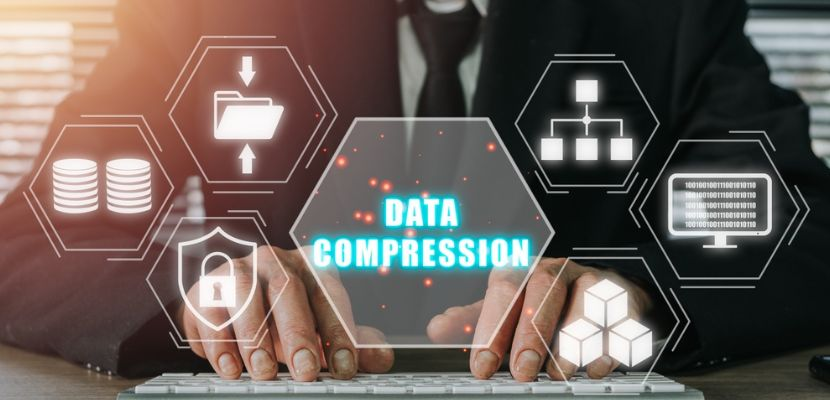

# Módulo 7: Generación de Datasets Sintéticos de Evaluación (Sinthetic Ground Truth Datasets)

## 1. Fundamentos Teóricos

En la construcción de sistemas RAG en producción, la mayor traba técnica no es la arquitectura, sino la **evaluación continua**. Para medir con precisión la fidelidad (*faithfulness*), la relevancia de respuesta (*answer relevancy*) y la precisión del contexto (*context precision*), es indispensable contar con un dataset de prueba estructurado conocido como **Ground Truth Dataset**.

Crear estos datasets manualmente demanda cientos de horas de trabajo por parte de expertos en el dominio. La solución moderna es la **generación sintética asistida por LLMs**, la cual utiliza un modelo generativo avanzado para leer el corpus corporativo y crear de forma automatizada tripletas compuestas por:

1. **Contexto ($C$):** El fragmento original extraído del documento (*chunk* de referencia).
2. **Pregunta / Query ($Q$):** Una pregunta plausible formulada en lenguaje natural que *solo* pueda responderse utilizando el contexto $C$.
3. **Respuesta Esperada / Ground Truth ($G$):** La respuesta ideal, fáctica y libre de alucinaciones basada estrictamente en $C$.


### Principio de Aislamiento Fáctico

Para garantizar la calidad del dataset de evaluación, el prompt del LLM generador debe forzar el **aislamiento fáctico**: el modelo no debe usar su conocimiento general previo, sino comportarse únicamente como un extractor rigoroso que convierte afirmaciones contenidas en el contexto en pares Pregunta/Respuesta.


In [10]:
import os
import sys
import json

# -------------------------------------------------------------------------
# Step 0: Instalación automática de dependencias si faltan
# -------------------------------------------------------------------------
try:
    import pydantic
    from langchain_google_genai import ChatGoogleGenerativeAI
except ModuleNotFoundError:
    print("📦 Instalando librerías requeridas...")
    !pip install -q -U langchain-google-genai langchain-core pydantic

from google.colab import userdata
from pydantic import BaseModel, Field
from typing import List
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.documents import Document

# -------------------------------------------------------------------------
# Step 1: Configuración segura de variables de entorno
# -------------------------------------------------------------------------
try:
    api_key_google = userdata.get('GOOGLE_API_KEY')
    os.environ["GOOGLE_API_KEY"] = api_key_google
    print("✅ Credenciales configuradas exitosamente.")
except Exception as e:
    print(f"❌ Error al cargar credenciales: {e}")


# -------------------------------------------------------------------------
# Step 2: Definición del Esquema del Dataset con Pydantic
# -------------------------------------------------------------------------
class EvaluationPair(BaseModel):
    pregunta: str = Field(
        description="Pregunta en lenguaje natural que se responde ÚNICAMENTE con el contexto proporcionado."
    )
    ground_truth: str = Field(
        description="Respuesta ideal, concisa y fáctica basada estrictamente en el contexto proporcionado."
    )

class SyntheticDataset(BaseModel):
    items: List[EvaluationPair] = Field(
        description="Lista de pares pregunta-respuesta sintéticos generados a partir del contexto."
    )

# -------------------------------------------------------------------------
# Step 3: Inicialización del Modelo con Salida Estructurada (Structured Output)
# -------------------------------------------------------------------------
llm = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash",
    temperature=0.2 # Temperatura baja para prevenir alucinaciones
)

# Forzamos al modelo a responder estrictamente respetando el esquema Pydantic
structured_llm = llm.with_structured_output(SyntheticDataset)

# -------------------------------------------------------------------------
# Step 4: Prompt Template para Generación Fáctica
# -------------------------------------------------------------------------
prompt_template = ChatPromptTemplate.from_messages([
    ("system", (
        "Eres un experto auditor de calidad para sistemas RAG. "
        "Tu tarea es analizar el siguiente TEXTO DE CONTEXTO y generar exactamente {num_questions} "
        "preguntas con sus respectivas respuestas ideales ('ground_truth').\n\n"
        "REGLAS STRICTAS:\n"
        "1. La pregunta debe poder responderse ÚNICAMENTE con la información explícita del texto.\n"
        "2. No asumas ni agregues información exterior al contexto.\n"
        "3. El 'ground_truth' debe ser preciso, directo y autocontenido."
    )),
    ("human", "TEXTO DE CONTEXTO:\n---\n{contexto}\n---")
])

chain = prompt_template | structured_llm

# -------------------------------------------------------------------------
# Step 5: Corpus Corporativo de Ejemplo (Chunks de la Asignatura)
# -------------------------------------------------------------------------
corpus_chunks = [
    Document(
        page_content=(
            "La arquitectura de recuperación híbrida combina la búsqueda por densidad vectorial (embeddings) "
            "con la búsqueda léxica basada en palabras clave (BM25). Esta combinación permite capturar "
            "tanto el significado semántico como términos técnicos específicos, códigos o identificadores exactos "
            "que los embeddings suelen omitir."
        ),
        metadata={"chunk_id": "CHK_001", "fuente": "modulo_arquitecturas.pdf"}
    ),
    Document(
        page_content=(
            "En el monitoreo con LangSmith, la métrica de latencia 'Time to First Token' (TTFT) mide el tiempo "
            "transcurrido desde que la solicitud ingresa al sistema hasta que el modelo emite el primer token "
            "de respuesta. Un TTFT superior a 1.5 segundos generalmente impacta negativamente la experiencia de usuario."
        ),
        metadata={"chunk_id": "CHK_002", "fuente": "manual_langsmith.pdf"}
    )
]

# -------------------------------------------------------------------------
# Step 6: Generación Automatizada del Dataset Sintético
# -------------------------------------------------------------------------
dataset_final = []

print("⚙️ Generando Dataset Sintético de Evaluación...\n")

for doc in corpus_chunks:
    chunk_text = doc.page_content
    chunk_id = doc.metadata["chunk_id"]

    # Generamos 2 pares Q&A por cada chunk
    resultado: SyntheticDataset = chain.invoke({
        "contexto": chunk_text,
        "num_questions": 2
    })

    # Ensamblamos la estructura completa del dataset de prueba
    for item in resultado.items:
        dataset_final.append({
            "chunk_id": chunk_id,
            "contexto": chunk_text,
            "pregunta": item.pregunta,
            "ground_truth": item.ground_truth
        })

# -------------------------------------------------------------------------
# Step 7: Visualización y Exportación de Resultados
# -------------------------------------------------------------------------
print("==================== DATASET DE PRUEBA SINTÉTICO GENERADO ====================\n")

for idx, sample in enumerate(dataset_final, 1):
    print(f"📌 MUESTRA #{idx} [Origen: {sample['chunk_id']}]")
    print(f"🔹 Contexto: \"{sample['contexto'][:80]}...\"")
    print(f"❓ Pregunta Sintética (Q): {sample['pregunta']}")
    print(f"🎯 Ground Truth (G): {sample['ground_truth']}\n" + "-"*70)

# Exportación a formato JSON para ser consumido por suites de evaluación (Ragas, TruLens, etc.)
json_output = json.dumps(dataset_final, ensure_ascii=False, indent=2)
print("\n💾 Vista previa del JSON generado (listo para benchmarks):")
print(json_output[:400] + "\n...")

✅ Credenciales configuradas exitosamente.
⚙️ Generando Dataset Sintético de Evaluación...

==================== DATASET DE PRUEBA SINTÉTICO GENERADO ====================

📌 MUESTRA #1 [Origen: CHK_001]
🔹 Contexto: "La arquitectura de recuperación híbrida combina la búsqueda por densidad vectori..."
❓ Pregunta Sintética (Q): ¿Qué métodos combina la arquitectura de recuperación híbrida?
🎯 Ground Truth (G): Combina la búsqueda por densidad vectorial (embeddings) con la búsqueda léxica basada en palabras clave (BM25).
----------------------------------------------------------------------
📌 MUESTRA #2 [Origen: CHK_001]
🔹 Contexto: "La arquitectura de recuperación híbrida combina la búsqueda por densidad vectori..."
❓ Pregunta Sintética (Q): ¿Qué elementos permite capturar la arquitectura híbrida que los embeddings suelen omitir?
🎯 Ground Truth (G): Permite capturar términos técnicos específicos, códigos o identificadores exactos.
-------------------------------------------------------------

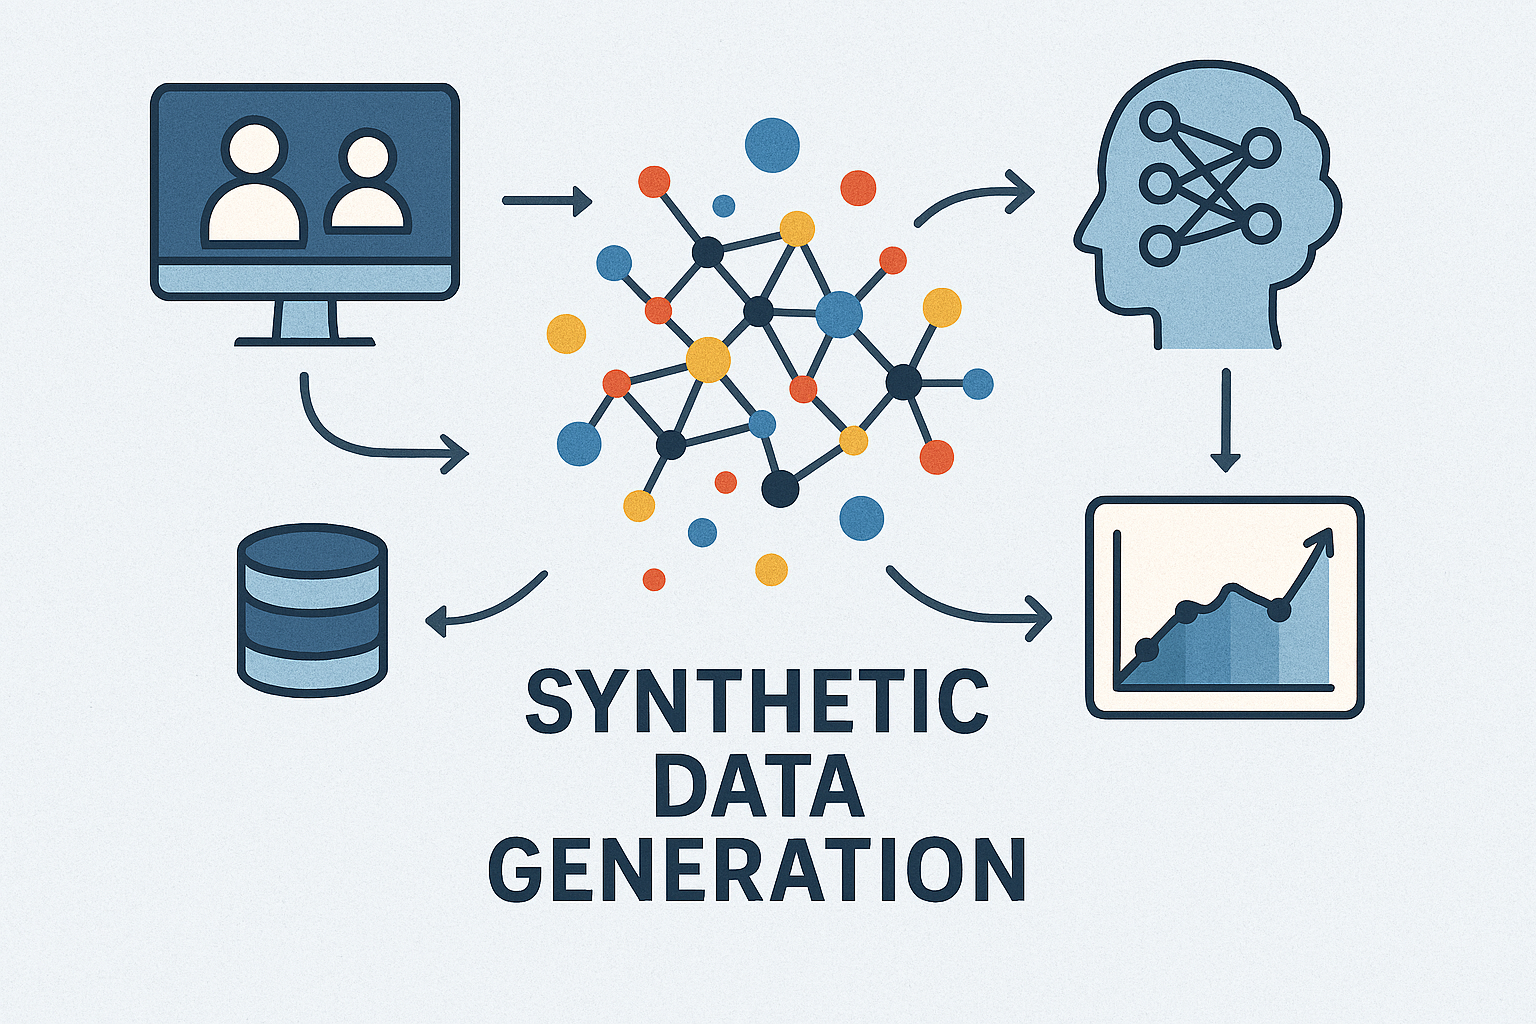

# Módulo 8: Estrategia de Auto-Corrección (*Self-RAG*) para Reintento de Consultas Defectuosas

## 1. Fundamentos Teóricos

Un sistema RAG pasivo o lineal sufre cuando la búsqueda inicial falla: si los documentos recuperados son irrelevantes, ambiguos o incompletos, el LLM generará inevitablemente una respuesta deficiente o una alucinación.

**Self-RAG** (Retrieval-Augmented Generation con Auto-Corrección) introduce un bucle de control adaptativo (*Evaluación y Bucle de Reintento*). En lugar de confiar ciegamente en el primer intento de búsqueda, el sistema evalúa la calidad del contexto recuperado y, si no cumple con el umbral requerido, reescribe la consulta del usuario (*Query Rewriting*) para ejecutar una nueva búsqueda mejorada.


### Componentes de la Arquitectura Self-RAG

1. **Grado de Relevancia (*****Retrieval Grader*****):** Un evaluador que analiza la consulta y los documentos recuperados para decidir si el contenido es suficiente.
2. **Reescritor de Consultas (*****Query Rewriter*****):** Un componente que transforma la pregunta original (frecuentemente vaga o mal formulada) en una versión semánticamente optimizada para el motor vectorial.
3. **Control de Ciclos:** Un límite de intentos (*max_retries*) para evitar bucles infinitos en caso de que la información realmente no exista en el corpus.


In [11]:
import os
import sys

try:
    import pydantic
    import faiss
    from langchain_google_genai import ChatGoogleGenerativeAI
except ModuleNotFoundError:
    print("📦 Instalando librerías requeridas...")
    !pip install -q -U langchain-google-genai langchain-community langchain-core faiss-cpu pydantic

from google.colab import userdata
from pydantic import BaseModel, Field
from langchain_google_genai import ChatGoogleGenerativeAI, GoogleGenerativeAIEmbeddings
from langchain_community.vectorstores import FAISS
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

# -------------------------------------------------------------------------
# Step 1: Configuración de credenciales de API
# -------------------------------------------------------------------------
try:
    api_key_google = userdata.get('GOOGLE_API_KEY')
    os.environ["GOOGLE_API_KEY"] = api_key_google
    print("✅ Credenciales configuradas exitosamente.")
except Exception as e:
    print(f"❌ Error al cargar credenciales: {e}")

# -------------------------------------------------------------------------
# Step 2: Componentes Base (LLM, Embeddings y Vector Store)
# -------------------------------------------------------------------------
llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash", temperature=0.0)
embeddings = GoogleGenerativeAIEmbeddings(model="gemini-embedding-2")

# Corpus corporativo de prueba
corpus = [
    Document(
        page_content="El protocolo de seguridad corporativa exige autenticación de doble factor (2FA) para todos los accesos VPN a la red interna.",
        metadata={"area": "Ciberseguridad", "doc_id": "SEC-01"}
    ),
    Document(
        page_content="Las solicitudes de vacaciones deben ingresarse en el portal RRHH con al menos 15 días de anticipación a la fecha deseada.",
        metadata={"area": "RRHH", "doc_id": "HR-02"}
    )
]

vectorstore = FAISS.from_documents(corpus, embeddings)
retriever = vectorstore.as_retriever(search_kwargs={"k": 1})

# -------------------------------------------------------------------------
# Step 3: Definición del Grado de Relevancia (Retrieval Grader)
# -------------------------------------------------------------------------
class GradeDocuments(BaseModel):
    binary_score: str = Field(
        description="Indica si los documentos recuperados son relevantes para la pregunta: 'yes' o 'no'."
    )
    justificacion: str = Field(
        description="Breve motivo de la calificación."
    )

structured_grader = llm.with_structured_output(GradeDocuments)

grader_prompt = ChatPromptTemplate.from_messages([
    ("system", (
        "Eres un evaluador que analiza la relevancia de un documento recuperado con respecto a una pregunta de usuario.\n"
        "Si el documento contiene palabras clave o significado semántico relacionado con la pregunta, evalúalo como 'yes'.\n"
        "De lo contrario, evalúalo como 'no'."
    )),
    ("human", "Documento recuperado:\n{documento}\n\nPregunta del usuario: {pregunta}")
])

grader_chain = grader_prompt | structured_grader

# -------------------------------------------------------------------------
# Step 4: Definición del Reescritor de Consultas (Query Rewriter)
# -------------------------------------------------------------------------
rewriter_prompt = ChatPromptTemplate.from_messages([
    ("system", (
        "Eres un experto en optimizar consultas para motores de búsqueda vectorial.\n"
        "Analiza la pregunta inicial del usuario y reescríbela para mejorar su claridad, "
        "agregando términos semánticos clave sin cambiar la intención original."
    )),
    ("human", "Pregunta inicial: {pregunta}\n\nPregunta optimizada:")
])

rewriter_chain = rewriter_prompt | llm | StrOutputParser()

# -------------------------------------------------------------------------
# Step 5: Bucle de Control Self-RAG (Auto-Corrección)
# -------------------------------------------------------------------------
def ejecutar_self_rag(pregunta_inicial: str, max_intentos: int = 2):
    consulta_actual = pregunta_inicial

    print(f"🚀 INICIANDO PIPELINE SELF-RAG")
    print(f"❓ Pregunta Inicial: '{pregunta_inicial}'\n")

    for intento in range(1, max_intentos + 1):
        print(f"--- 🔄 INTENTO {intento} de {max_intentos} ---")
        print(f"🔍 Consulta ejecutada en VectorStore: '{consulta_actual}'")

        # 1. Recuperación
        docs_recuperados = retriever.invoke(consulta_actual)
        if not docs_recuperados:
            print("⚠️ No se encontraron documentos.")
            documento_texto = ""
        else:
            documento_texto = docs_recuperados[0].page_content
            print(f"📄 Documento Recuperado: \"{documento_texto}\"")

        # 2. Evaluación de Relevancia
        evaluacion = grader_chain.invoke({
            "documento": documento_texto,
            "pregunta": pregunta_inicial
        })

        print(f"📊 Evaluación de Relevancia: [{evaluacion.binary_score.upper()}] - {evaluacion.justificacion}")

        # 3. Decisión del Flujo
        if evaluacion.binary_score.lower() == "yes":
            print("\n✅ Contexto validado. Generando respuesta final con LLM...")
            generation_prompt = ChatPromptTemplate.from_template(
                "Responde la pregunta basándote únicamente en el contexto:\nContexto: {contexto}\nPregunta: {pregunta}"
            )
            gen_chain = generation_prompt | llm | StrOutputParser()
            respuesta = gen_chain.invoke({"contexto": documento_texto, "pregunta": pregunta_inicial})
            return respuesta
        else:
            print("❌ El contexto no es relevante.")
            if intento < max_intentos:
                print("🛠️ Aplicando Query Rewriting para reintentar búsqueda...")
                consulta_actual = rewriter_chain.invoke({"pregunta": consulta_actual})
                print(f"✏️ Nueva Consulta Optimizada: '{consulta_actual}'\n")
            else:
                print("\n⚠️ Se alcanzó el número máximo de reintentos sin encontrar contexto adecuado.")
                return "Lo siento, no encontré información suficiente en la base de conocimiento corporativa para responder tu pregunta."

# -------------------------------------------------------------------------
# Step 6: Prueba con Consulta Defectuosa/Ambigua
# -------------------------------------------------------------------------
# La pregunta "SFA" o mala redacción del 2FA no matchea directo a la primera
pregunta_ambigua = "¿Qué necesito para conectarme a la red remota VPN desde la casa?"
respuesta_final = ejecutar_self_rag(pregunta_ambigua)

print("\n==================== RESPUESTA FINAL OBTENIDA ====================")
print(respuesta_final)

✅ Credenciales configuradas exitosamente.
🚀 INICIANDO PIPELINE SELF-RAG
❓ Pregunta Inicial: '¿Qué necesito para conectarme a la red remota VPN desde la casa?'

--- 🔄 INTENTO 1 de 2 ---
🔍 Consulta ejecutada en VectorStore: '¿Qué necesito para conectarme a la red remota VPN desde la casa?'
📄 Documento Recuperado: "El protocolo de seguridad corporativa exige autenticación de doble factor (2FA) para todos los accesos VPN a la red interna."
📊 Evaluación de Relevancia: [YES] - El documento es relevante porque indica directamente que se requiere la autenticación de doble factor (2FA) para acceder a la red interna a través de la VPN.

✅ Contexto validado. Generando respuesta final con LLM...

==================== RESPUESTA FINAL OBTENIDA ====================
Basándote únicamente en el contexto proporcionado, para conectarte a la VPN necesitas **autenticación de doble factor (2FA)**.


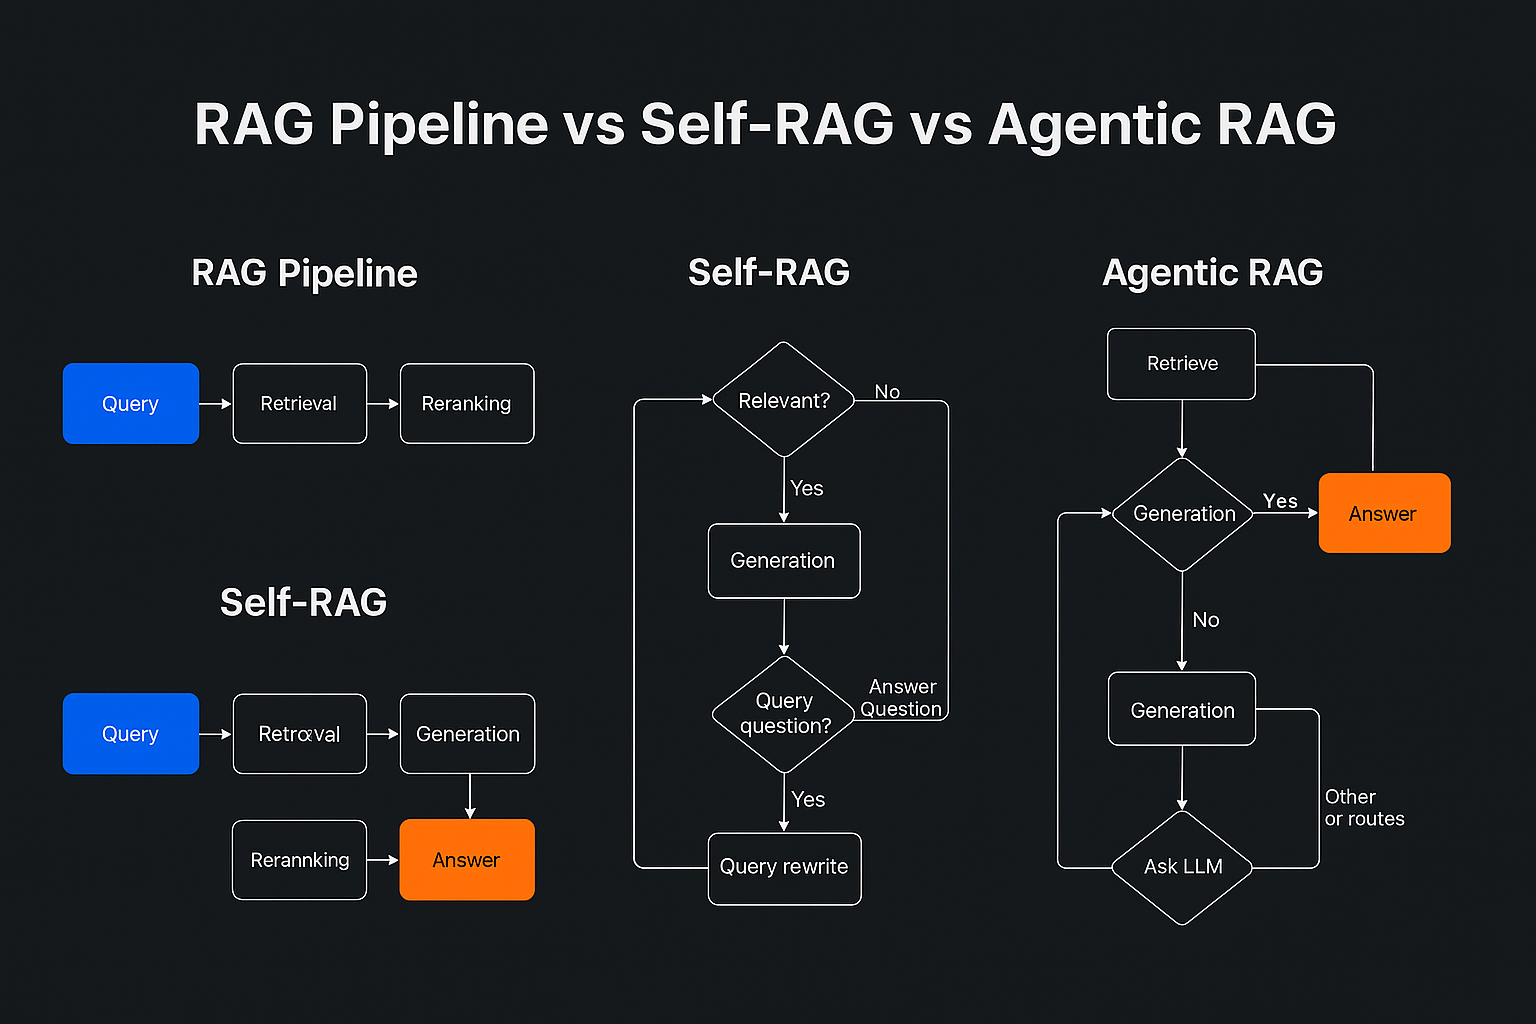

# Módulo 9: Optimización del Tamaño de Ventana de Contexto y Gestión de Historial Conversacional

## 1. Fundamentos Teóricos

En aplicaciones RAG interactivas (como asistentes virtuales o chatbots de soporte), las consultas del usuario raramente son independientes; dependen del contexto de los turnos previos de la conversación. Sin embargo, inyectar todo el historial conversacional junto con los documentos recuperados presenta tres desafíos críticos:

1. **Problema de la Consulta Ambigua (*****Follow-up Query Anaphora*****):** Preguntas como *"¿Cuáles son sus requisitos?"* o *"¿Cuándo vence?"* carecen de significado para el motor de búsqueda vectorial si no se resuelven los pronombres o referencias del historial anterior.
2. **Fenómeno** ***Lost in the Middle*** **y Saturación de Contexto:** A medida que la ventana de contexto crece, la atención del LLM disminuye hacia los fragmentos ubicados en el centro del *prompt*, reduciendo la precisión de las respuestas.
3. **Costo de Tokens y Latencia Escalable:** Reenviar conversaciones largas incrementa exponencialmente los costos por llamada a la API y ralentiza el tiempo de respuesta (*Time To First Token*).


### Estrategias de Gestión de Memoria

* **Reformulación de Consultas (*****Contextualize Question*****):** Transforma una pregunta dependiente del historial en una consulta autónoma (*standalone query*) antes de consultar la base vectorial.
* **Memoria por Ventana Deslizante / Recorte (*****Trim Messages*****):** Conserva únicamente los últimos $N$ mensajes o tokens del historial para evitar la saturación de la ventana de contexto.


In [12]:
import os
import sys

# -------------------------------------------------------------------------
# Step 0: Instalación automática de dependencias si faltan
# -------------------------------------------------------------------------
try:
    import faiss
    from langchain_google_genai import ChatGoogleGenerativeAI
except ModuleNotFoundError:
    print("📦 Instalando librerías requeridas...")
    !pip install -q -U langchain-google-genai langchain-community langchain-core faiss-cpu

from google.colab import userdata
from langchain_google_genai import ChatGoogleGenerativeAI, GoogleGenerativeAIEmbeddings
from langchain_community.vectorstores import FAISS
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder
from langchain_core.messages import HumanMessage, AIMessage, trim_messages
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnablePassthrough

# -------------------------------------------------------------------------
# Step 1: Configuración de credenciales de API
# -------------------------------------------------------------------------
try:
    api_key_google = userdata.get('GOOGLE_API_KEY')
    os.environ["GOOGLE_API_KEY"] = api_key_google
    print("✅ Credenciales configuradas exitosamente.")
except Exception as e:
    print(f"❌ Error al cargar credenciales: {e}")

# -------------------------------------------------------------------------
# Step 2: Configuración del Vector Store y LLM
# -------------------------------------------------------------------------
llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash", temperature=0.0)
embeddings = GoogleGenerativeAIEmbeddings(model="gemini-embedding-2")

corpus = [
    Document(
        page_content="El protocolo de seguridad corporativa exige autenticación de doble factor (2FA) para todos los accesos VPN a la red interna.",
        metadata={"categoria": "Seguridad"}
    ),
    Document(
        page_content="Las licencias médicas deben presentarse en el portal de Recursos Humanos dentro de las primeras 48 horas de emisión.",
        metadata={"categoria": "RRHH"}
    )
]

vectorstore = FAISS.from_documents(corpus, embeddings)
retriever = vectorstore.as_retriever(search_kwargs={"k": 1})


# -------------------------------------------------------------------------
# Step 3: Cadena de Reformulación de Pregunta (Contextualizer)
# -------------------------------------------------------------------------
contextualize_q_system_prompt = (
    "Dada la siguiente conversación y una pregunta reciente del usuario que puede hacer "
    "referencia al contexto anterior, formula una pregunta independiente que se pueda entender "
    "sin el historial de chat. NO respondas la pregunta, solo reformúlala si es necesario "
    "y si no requiere cambios, devuélvela tal como está."
)

contextualize_q_prompt = ChatPromptTemplate.from_messages([
    ("system", contextualize_q_system_prompt),
    MessagesPlaceholder("chat_history"),
    ("human", "{input}"),
])

history_aware_retriever = contextualize_q_prompt | llm | StrOutputParser()

# -------------------------------------------------------------------------
# Step 4: Cadena Principal de Respuesta RAG
# -------------------------------------------------------------------------
system_prompt = (
    "Eres un asistente corporativo. Responde la pregunta del usuario utilizando únicamente "
    "el siguiente contexto recuperado. Si no sabes la respuesta, di que no la sabes.\n\n"
    "Contexto:\n{context}"
)

qa_prompt = ChatPromptTemplate.from_messages([
    ("system", system_prompt),
    MessagesPlaceholder("chat_history"),
    ("human", "{input}"),
])

# -------------------------------------------------------------------------
# Step 5: Función de Ejecución Conversacional con Ventana Recortada
# -------------------------------------------------------------------------
def responder_conversacion(pregunta: str, historial: list):
    # Truncamos el historial a los últimos 4 mensajes para optimizar la ventana de contexto
    historial_recortado = trim_messages(
        historial,
        max_tokens=4,
        token_counter=len, # Medición por cantidad de mensajes
        strategy="last",
        start_on="human"
    )

    # 1. Reformular pregunta considerando el historial
    if historial_recortado:
        pregunta_standalone = history_aware_retriever.invoke({
            "chat_history": historial_recortado,
            "input": pregunta
        })
        print(f"🔄 Pregunta Reformulada para Búsqueda: '{pregunta_standalone}'")
    else:
        pregunta_standalone = pregunta

    # 2. Recuperar documentos relevantes con la pregunta autónoma
    docs_recuperados = retriever.invoke(pregunta_standalone)
    contexto_texto = "\n\n".join(doc.page_content for doc in docs_recuperados)

    # 3. Generar la respuesta usando el QA Chain
    qa_chain = qa_prompt | llm | StrOutputParser()
    respuesta = qa_chain.invoke({
        "context": contexto_texto,
        "chat_history": historial_recortado,
        "input": pregunta
    })

    # Actualizar historial
    historial.append(HumanMessage(content=pregunta))
    historial.append(AIMessage(content=respuesta))

    return respuesta, docs_recuperados[0].page_content

# -------------------------------------------------------------------------
# Step 6: Simulación de Chat Multiturno
# -------------------------------------------------------------------------
historial_chat = []

print("=== TURNO 1 ===")
p1 = "¿Qué exige el protocolo de seguridad para la conexión VPN?"
resp1, ctx1 = responder_conversacion(p1, historial_chat)
print(f"👤 User: {p1}")
print(f"🤖 AI: {resp1}\n")

print("=== TURNO 2 (Pregunta con Referencia Anafórica) ===")
p2 = "¿Es obligatorio usar 2FA para eso?"
resp2, ctx2 = responder_conversacion(p2, historial_chat)
print(f"👤 User: {p2}")
print(f"🤖 AI: {resp2}\n")

✅ Credenciales configuradas exitosamente.
=== TURNO 1 ===
👤 User: ¿Qué exige el protocolo de seguridad para la conexión VPN?
🤖 AI: El protocolo de seguridad corporativa exige autenticación de doble factor (2FA) para todos los accesos VPN a la red interna.

=== TURNO 2 (Pregunta con Referencia Anafórica) ===
🔄 Pregunta Reformulada para Búsqueda: '¿Es obligatorio usar la autenticación de doble factor (2FA) para la conexión VPN?'
👤 User: ¿Es obligatorio usar 2FA para eso?
🤖 AI: Sí, es obligatorio, ya que el protocolo de seguridad corporativa exige la autenticación de doble factor (2FA) para todos los accesos VPN a la red interna.



# Módulo 10: Construcción de un Arquetipo Integrado de Evaluación Cuantitativa de RAG

## 1. Fundamentos Teóricos

Llegados a este punto del curso, hemos implementado componentes avanzados de un pipeline RAG: estrategias de optimización de contexto, bucles de auto-corrección (*Self-RAG*) y resolución de anáforas en entornos conversacionales. Sin embargo, para validar cualquier mejora o ajuste fino en producción (*fine-tuning*, cambio de embeddings, variación del valor de $k$, o reescritura de prompts), es imprescindible contar con un **Arquetipo Integrado de Evaluación Cuantitativa**.

Un arquetipo de evaluación actúa como un arnés de pruebas (*test harness*) que somete al pipeline RAG a un conjunto de datos de prueba (*Golden Dataset*), ejecutando métricas automatizadas en lote y generando reportes estructurados para el monitoreo y toma de decisiones.


### Componentes Clave del Arquetipo

1. **Dataset de Referencia (*****Golden Dataset*****):** Muestra representativa de preguntas reales de usuarios acompañadas de las respuestas de referencia (*Ground Truth*).
2. **Evaluador Estructurado (*****LLM-as-a-Judge*****):** Un modelo evaluador que califica objetivamente cada ejecución en tres dimensiones: *Relevancia del Contexto*, *Fidelidad (Alucinaciones)* y *Relevancia de la Respuesta*.
3. **Consolidador de Métricas:** Módulo encargado de calcular el promedio global (*Mean Score*), la latencia total del sistema y exportar los resultados a un formato analítico estructurado (DataFrame / CSV).


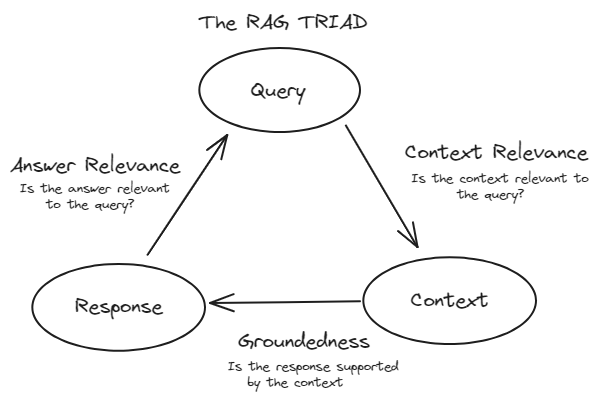

In [ ]:
import os
import sys
import time
import pandas as pd

# -------------------------------------------------------------------------
# Step 0: Instalación de dependencias requeridas
# -------------------------------------------------------------------------
try:
    import faiss
    import pydantic
    from langchain_google_genai import ChatGoogleGenerativeAI
except ModuleNotFoundError:
    print("📦 Instalando librerías requeridas...")
    !pip install -q -U langchain-google-genai langchain-community langchain-core faiss-cpu pydantic pandas

from google.colab import userdata
from pydantic import BaseModel, Field
from langchain_google_genai import ChatGoogleGenerativeAI, GoogleGenerativeAIEmbeddings
from langchain_community.vectorstores import FAISS
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

# -------------------------------------------------------------------------
# Step 1: Configuración de Credenciales
# -------------------------------------------------------------------------
try:
    api_key_google = userdata.get('GOOGLE_API_KEY')
    os.environ["GOOGLE_API_KEY"] = api_key_google
    print("✅ Credenciales configuradas exitosamente.")
except Exception as e:
    print(f"❌ Error al cargar credenciales: {e}")

# -------------------------------------------------------------------------
# Step 2: Inicialización de la Base de Conocimiento RAG
# -------------------------------------------------------------------------
embeddings = GoogleGenerativeAIEmbeddings(model="models/gemini-embedding-2")
llm_rag = ChatGoogleGenerativeAI(model="gemini-3.5-flash", temperature=0.0)

corpus = [
    Document(
        page_content="El horario de atención presencial de Soporte TI es de Lunes a Viernes de 08:30 a 17:30 hrs en el piso 3 del Edificio Central.",
        metadata={"id": "DOC-TI-01"}
    ),
    Document(
        page_content="Para solicitar licencias de software especializado (ej. SPSS, AutoCAD), se requiere la aprobación del Director del Departamento a través del ticket de Mesa de Ayuda.",
        metadata={"id": "DOC-TI-02"}
    ),
    Document(
        page_content="El límite máximo de almacenamiento en la nube corporativa es de 1 TB por usuario de la comunidad académica.",
        metadata={"id": "DOC-TI-03"}
    )
]

vectorstore = FAISS.from_documents(corpus, embeddings)
retriever = vectorstore.as_retriever(search_kwargs={"k": 1})

# Pipeline RAG
rag_prompt = ChatPromptTemplate.from_template(
    "Responde la pregunta basándote únicamente en el contexto:\nContexto: {contexto}\nPregunta: {pregunta}"
)
rag_chain = rag_prompt | llm_rag | StrOutputParser()

def ejecutar_pipeline_rag(pregunta: str):
    start_time = time.perf_counter()
    docs = retriever.invoke(pregunta)
    contexto = docs[0].page_content if docs else ""
    respuesta = rag_chain.invoke({"contexto": contexto, "pregunta": pregunta})
    latencia_ms = (time.perf_counter() - start_time) * 1000
    return respuesta, contexto, round(latencia_ms, 2)

# -------------------------------------------------------------------------
# Step 3: Definición del Evaluador Cuantitativo (LLM-as-a-Judge)
# -------------------------------------------------------------------------
class EvaluacionRAG(BaseModel):
    relevancia_contexto: float = Field(description="Puntuación de 0.0 a 1.0 sobre si el contexto es relevante a la pregunta.")
    fidelidad: float = Field(description="Puntuación de 0.0 a 1.0 sobre si la respuesta está libre de alucinaciones y basada en el contexto.")
    relevancia_respuesta: float = Field(description="Puntuación de 0.0 a 1.0 sobre si la respuesta atiende directamente la solicitud.")
    observacion: str = Field(description="Breve diagnóstico cualitativo de la evaluación.")

llm_juez = ChatGoogleGenerativeAI(model="gemini-3.5-flash", temperature=0.0)
structured_judge = llm_juez.with_structured_output(EvaluacionRAG)

judge_prompt = ChatPromptTemplate.from_messages([
    ("system", (
        "Eres un auditor técnico riguroso de sistemas RAG. Evalúa la calidad del contexto y de la respuesta generada.\n"
        "Devuelve un valor de 0.0 a 1.0 para cada una de las 3 métricas de la Triada RAG (Relevancia Contexto, Fidelidad, Relevancia Respuesta)."
    )),
    ("human", "Pregunta: {pregunta}\nContexto Recuperado: {contexto}\nRespuesta Generada: {respuesta}")
])

judge_chain = judge_prompt | structured_judge

# -------------------------------------------------------------------------
# Step 4: Ejecución del Harness de Evaluación en Lote (Golden Dataset)
# -------------------------------------------------------------------------
golden_dataset = [
    {
        "id": 1,
        "pregunta": "¿En qué horario y lugar atiende Soporte TI?",
        "tipo": "Caso Ideal"
    },
    {
        "id": 2,
        "pregunta": "¿Cómo puedo pedir la licencia del programa SPSS?",
        "tipo": "Caso Ideal"
    },
    {
        "id": 3,
        "pregunta": "¿Cuántos Terabytes tengo disponibles en Drive y cuál es el procedimiento para aumentar la cuota a 5 TB?",
        "tipo": "Consulta Parcialmente Fuera de Dominio"
    }
]

print("⚖️ EJECUTANDO ARQUETIPO DE EVALUACIÓN CUANTITATIVA EN LOTE...\n")

resultados_evaluacion = []

for item in golden_dataset:
    pregunta = item["pregunta"]

    # 1. Ejecutar RAG
    respuesta, contexto, latencia = ejecutar_pipeline_rag(pregunta)

    # 2. Evaluar con el Juez
    eval_metricas = judge_chain.invoke({
        "pregunta": pregunta,
        "contexto": contexto,
        "respuesta": respuesta
    })

    # 3. Registrar Resultados
    resultados_evaluacion.append({
        "ID": item["id"],
        "Tipo": item["tipo"],
        "Pregunta": pregunta,
        "Respuesta Generada": respuesta,
        "Latencia (ms)": latencia,
        "Rel. Contexto": eval_metricas.relevancia_contexto,
        "Fidelidad": eval_metricas.fidelidad,
        "Rel. Respuesta": eval_metricas.relevancia_respuesta,
        "Observación": eval_metricas.observacion
    })

# Convertir a DataFrame de Pandas
df_resultados = pd.DataFrame(resultados_evaluacion)

# -------------------------------------------------------------------------
# Step 5: Reporte Cuantitativo Consolidado
# -------------------------------------------------------------------------
print("================================ MATRIX DE EVALUACIÓN RAG ================================")
print(df_resultados[["ID", "Tipo", "Latencia (ms)", "Rel. Contexto", "Fidelidad", "Rel. Respuesta"]].to_string(index=False))

print("\n================================ RESUMEN EJECUTIVO (PROMEDIOS) ================================")
promedios = df_resultados[["Latencia (ms)", "Rel. Contexto", "Fidelidad", "Rel. Respuesta"]].mean()
print(f"⏱️ Latencia Promedio:             {promedios['Latencia (ms)']:.2f} ms")
print(f"🎯 Relevancia de Contexto Media:  {promedios['Rel. Contexto']:.2f} / 1.0")
print(f"🛡️ Fidelidad Media (Sin Alucin):  {promedios['Fidelidad']:.2f} / 1.0")
print(f"💬 Relevancia de Respuesta Media: {promedios['Rel. Respuesta']:.2f} / 1.0")

# Exportar a CSV para análisis
df_resultados.to_csv("reporte_evaluación_rag_modulo10.csv", index=False)
print("\n💾 Reporte exportado exitosamente como 'reporte_evaluación_rag_modulo10.csv'.")